<a href="https://colab.research.google.com/github/chris1982-arch/D7041E-Lab1/blob/main/Lab1_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# --- Task 1.1: Loading my own image dataset ---

import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import drive

# I mount my Google Drive so Colab can read my photos
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/Lab1_D7041E/my_dataset'
IMG_SIZE = 64   # I resize all photos to the same size so they fit in one array

# I save all my figures here, so I can use them in my report
FIG_DIR = '/content/drive/MyDrive/Lab1_D7041E/figures'
os.makedirs(FIG_DIR, exist_ok=True)

images = []
labels = []

# I sort the file names so the order is the same every time I run this
for fname in sorted(os.listdir(DATA_DIR)):
    if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
        continue  # I skip anything that is not an image

    # I open each photo and make sure it has 3 colour channels (RGB)
    img = Image.open(os.path.join(DATA_DIR, fname)).convert('RGB')

    # My photos have different shapes (1200x1600 and 716x1600),
    # so I resize all of them to 64x64
    img = img.resize((IMG_SIZE, IMG_SIZE))

    images.append(np.array(img))

    # I named my files as "category_number.jpg",
    # so I take the label from the part before "_" (e.g. "cup_3.jpg" -> "cup")
    labels.append(fname.split('_')[0])

# I stack my list of images into one array of shape (n, x, y, 3)
X = np.stack(images)
y = np.array(labels)

print('Dataset shape:', X.shape)          # I expect (25, 64, 64, 3)
print('Classes:', np.unique(y))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (25, 64, 64, 3)
Classes: ['ashtray' 'candle' 'coaster' 'cup' 'glass']


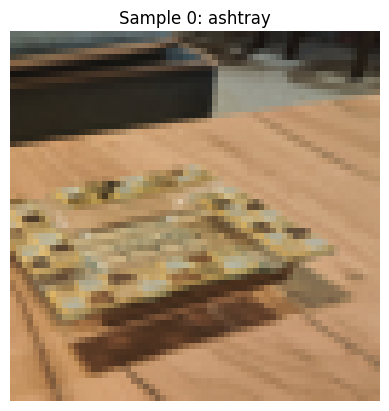

In [4]:
# --- Task 1.1.2: My function for plotting a sample by index ---

def PlotSample(index):
    """I show the image at position `index` with its label as the title,
    and I also save it to my figures folder."""
    plt.imshow(X[index])
    plt.title(f'Sample {index}: {y[index]}')
    plt.axis('off')
    # I save before show(), otherwise the saved figure would be empty
    plt.savefig(os.path.join(FIG_DIR, f'sample_{index}.png'), bbox_inches='tight')
    plt.show()

PlotSample(0)

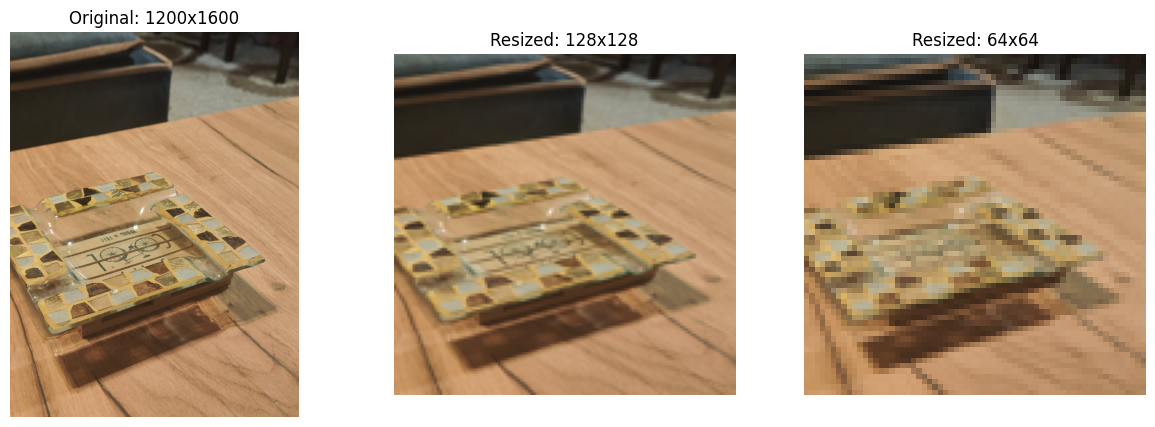

In [5]:
# --- Extra: Comparing my original photo with two resize options (128 vs 64) ---

# I pick the first image file from my sorted list
fname = sorted(f for f in os.listdir(DATA_DIR)
               if f.lower().endswith(('.jpg', '.jpeg', '.png')))[0]

original = Image.open(os.path.join(DATA_DIR, fname)).convert('RGB')

# I create two resized versions of the same photo
img_128 = original.resize((128, 128))
img_64  = original.resize((64, 64))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

# Left: the original photo as I took it with my phone
ax[0].imshow(original)
ax[0].set_title(f'Original: {original.size[0]}x{original.size[1]}')

# Middle: resized to 128x128
ax[1].imshow(img_128)
ax[1].set_title('Resized: 128x128')

# Right: resized to 64x64 (the size I use in my dataset)
ax[2].imshow(img_64)
ax[2].set_title('Resized: 64x64')

for a in ax:
    a.axis('off')

plt.savefig(os.path.join(FIG_DIR, 'resize_comparison.png'), bbox_inches='tight')
plt.show()

# My observations:
# 1) Both resized images are distorted, because I forced a rectangular photo into a square.
# 2) The 64x64 image is more pixelated than the 128x128 one, because it keeps fewer pixels.
# 3) In 128x128 each image has 128*128*3 = 49,152 values, in 64x64 only 12,288 (4 times fewer).
# I chose 64x64 because the object is still recognisable and my code runs much faster.

In [6]:
# --- Task 1.1.3: Preprocessing my dataset (following the hadrienj tutorial) ---

# With 64x64 images I would have 64*64*3 = 12,288 pixels, so the pixel covariance
# matrix would be 12,288 x 12,288 (too big and slow for Colab).
# I resize to 32x32 -> 3,072 pixels, the same size as CIFAR-10 in the tutorial.
PRE_SIZE = 32
X_small = np.stack([np.array(Image.fromarray(img).resize((PRE_SIZE, PRE_SIZE)))
                    for img in X])

# I flatten every image into one row: (25, 32, 32, 3) -> (25, 3072)
# Rows are my images (observations), columns are pixels (features)
X_flat = X_small.reshape(X_small.shape[0], -1).astype(float)
print('Flattened shape:', X_flat.shape)

# Helper: I reshape one row back to (32, 32, 3) so imshow can display it
def plotImage(row, ax, title=''):
    ax.imshow(row.reshape(PRE_SIZE, PRE_SIZE, 3))
    ax.set_title(title)
    ax.axis('off')

# I pick one image from each of my 5 classes to follow through all the steps
# (files are sorted alphabetically, 5 per class -> indices 0, 5, 10, 15, 20)
SAMPLES = [0, 5, 10, 15, 20]

Flattened shape: (25, 3072)


In [7]:
# --- Step 1: Rescaling pixel values to the range [0, 1] ---

# My pixels are between 0 and 255, so I divide by 255 (the minimum is already 0)
X_scaled = X_flat / 255.0
print('min:', X_scaled.min(), ' max:', X_scaled.max())   # I expect 0.0 and 1.0

min: 0.0392156862745098  max: 0.984313725490196


In [8]:
# --- Step 2: Mean normalization (per-pixel mean subtraction) ---

# For every pixel I compute its mean across all my 25 images (axis=0)
pixel_means = X_scaled.mean(axis=0)
print('Number of pixel means:', pixel_means.shape)        # (3072,)
print('First pixel means:', pixel_means[:5])

# I subtract each pixel's mean, so every pixel (feature) is centred around 0
X_norm = X_scaled - pixel_means

# Check: the new means should be (almost) zero
print('Means after centring:', X_norm.mean(axis=0)[:5])

Number of pixel means: (3072,)
First pixel means: [0.376      0.368      0.33584314 0.36862745 0.35890196]
Means after centring: [-9.99200722e-18  1.88737914e-17 -9.54791801e-17 -1.55431223e-17
 -2.10942375e-17]


In [9]:
# --- Step 3: Standardization ---

# I divide each centred pixel by its standard deviation, so all pixels have the same scale
# I add a tiny value to avoid division by zero, in case a pixel never changes
pixel_std = X_scaled.std(axis=0)
X_std = X_norm / (pixel_std + 1e-8)

print('Mean of first pixels:', X_std.mean(axis=0)[:3])   # ~0
print('Std of first pixels: ', X_std.std(axis=0)[:3])    # ~1

Mean of first pixels: [-2.66453526e-17  8.88178420e-17 -6.66133815e-16]
Std of first pixels:  [0.99999994 0.99999994 0.99999993]


Covariance shape: (3072, 3072)
U shape: (3072, 3072)  S shape: (3072,)


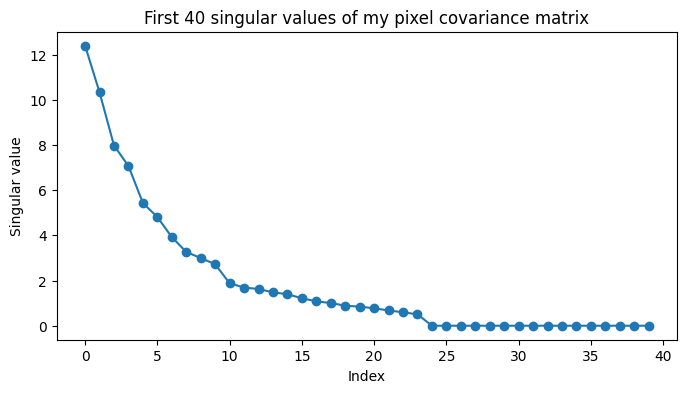

Non-zero singular values: 24


In [10]:
# --- Step 4: Covariance matrix of the pixels and SVD ---

# rowvar=False -> columns (pixels) are the variables, rows (images) are observations
cov = np.cov(X_norm, rowvar=False)
print('Covariance shape:', cov.shape)                     # (3072, 3072)

# I decompose the covariance matrix with SVD (this may take ~30 seconds)
U, S, V = np.linalg.svd(cov)
print('U shape:', U.shape, ' S shape:', S.shape)

# I plot the singular values to see how much information each direction carries
plt.figure(figsize=(8, 4))
plt.plot(S[:40], 'o-')
plt.title('First 40 singular values of my pixel covariance matrix')
plt.xlabel('Index')
plt.ylabel('Singular value')
plt.savefig(os.path.join(FIG_DIR, 'singular_values.png'), bbox_inches='tight')
plt.show()

# Observation: I have only 25 images, so after centring there can be
# at most 24 non-zero singular values. All the rest are ~0.
print('Non-zero singular values:', np.sum(S > 1e-10))

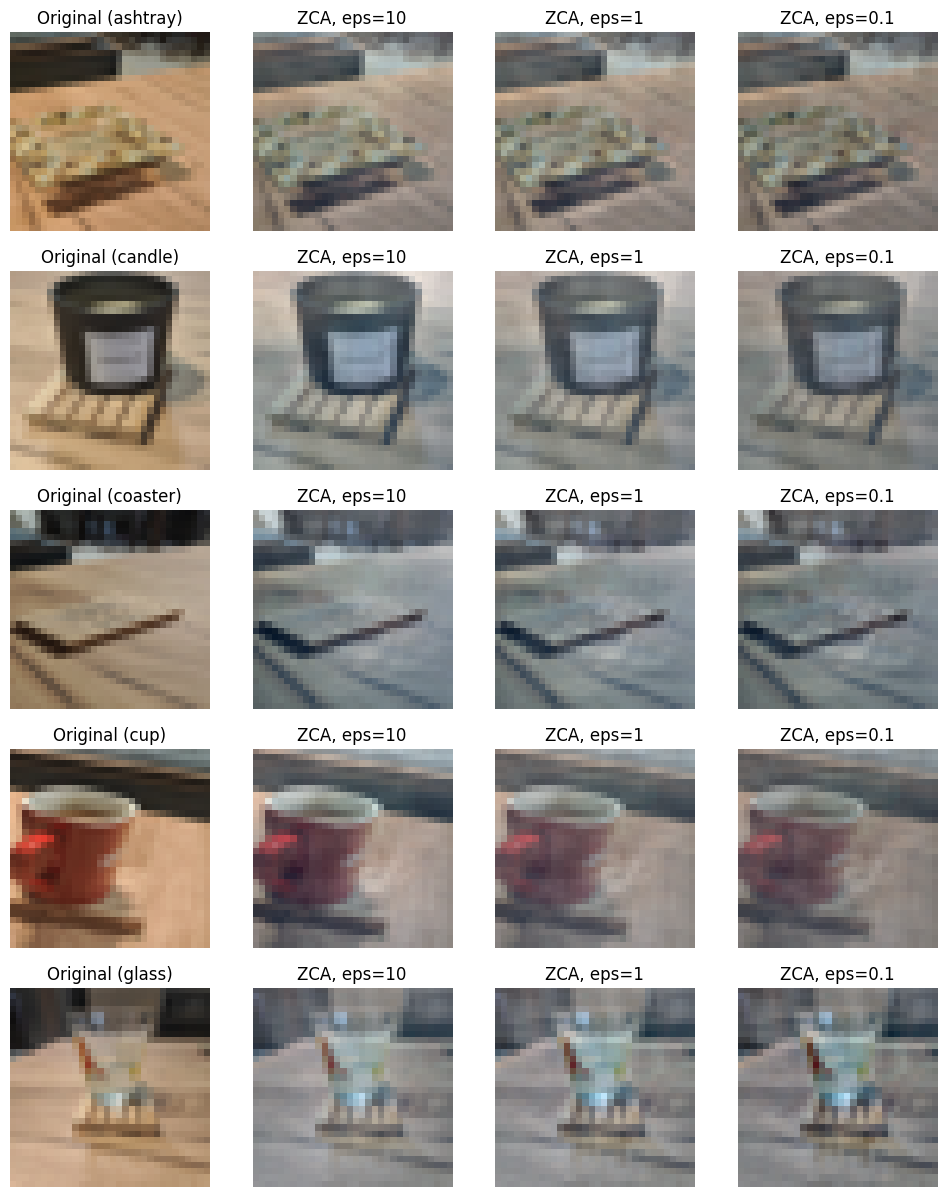

In [12]:
# --- Step 5: ZCA whitening (Pal & Sudeep, 2016) ---
# X_ZCA = U . diag(1 / sqrt(S + epsilon)) . U^T . X

def zca(X_centered, U, S, epsilon):
    X_zca = U.dot(np.diag(1.0 / np.sqrt(S + epsilon))).dot(U.T).dot(X_centered.T).T
    # I rescale to [0, 1] so I can display the result as an image
    return (X_zca - X_zca.min()) / (X_zca.max() - X_zca.min())

# I try three values of the whitening coefficient epsilon
EPSILONS = [10, 1, 0.1]
X_zca = {eps: zca(X_norm, U, S, eps) for eps in EPSILONS}

# I show each sample: original + whitened with each epsilon
fig, ax = plt.subplots(len(SAMPLES), 1 + len(EPSILONS), figsize=(12, 15))
for r, i in enumerate(SAMPLES):
    plotImage(X_scaled[i], ax[r, 0], f'Original ({y[i]})')
    for c, eps in enumerate(EPSILONS):
        plotImage(X_zca[eps][i], ax[r, c + 1], f'ZCA, eps={eps}')

plt.savefig(os.path.join(FIG_DIR, 'zca_whitening.png'), bbox_inches='tight')
plt.show()

# My observations:
# 1) My covariance matrix has only 24 non-zero singular values (25 images - 1),
#    ranging from about 0.5 to 12.
# 2) Small epsilons (0.1, 0.01, 0.001) give almost identical results, because
#    they are negligible compared to my singular values.
# # 3) The effect of epsilon is subtle: with eps=10 the result is smoother and
#    closer to the original, with eps=0.1 small details and textures (e.g. the
#    wood grain of the table) are amplified and the image looks grainier.
# 4) Whitening mainly removed the common colour and lighting (washed-out colours).
#    In the tutorial (1000 images) whitening highlights edges; with only 25 images
#    my covariance cannot capture the relations between neighbouring pixels,
#    so the edge effect is much weaker.

In [13]:
# --- Task 1.2.1: Loading somebody else's dataset (vecs.npy) ---

VEC_PATH = '/content/drive/MyDrive/Lab1_D7041E/vecs.npy'

# The file stores a Python dictionary, not a plain array, so I need allow_pickle=True.
# np.load returns it wrapped in a 0-dimensional object array, so I unwrap it with .item()
data = np.load(VEC_PATH, allow_pickle=True).item()

# I explore the structure step by step
print('Outer type:', type(data))
print('Positions (outer keys):', list(data.keys()))
print('Digits (inner keys of 1_pos):', list(data['1_pos'].keys()))

sample = data['1_pos'][0]
print('Type of one inner value:', type(sample))           # a Python list, not an array
print('Samples of digit 0 in 1_pos:', len(sample))
print('Embedding size:', np.array(sample).shape[1])       # 1024

# I check the total number of samples (the e-mail says ~11 thousand)
total = sum(len(data[p][d]) for p in data for d in data[p])
print('Total samples in the file:', total)

Outer type: <class 'dict'>
Positions (outer keys): ['1_pos', '2_pos', '3_pos', '4_pos', '5_pos', '6_pos', '7_pos', '8_pos', '9_pos']
Digits (inner keys of 1_pos): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Type of one inner value: <class 'list'>
Samples of digit 0 in 1_pos: 122
Embedding size: 1024
Total samples in the file: 11302


In [14]:
# --- Task 1.2.2: Forming the embeddings and labels arrays for any position ---

def get_position_data(data, position):
    """I return two arrays for one position on the scene:
    X -> embeddings, shape (n_samples, 1024)
    y -> labels (the digit), shape (n_samples,)
    The order is the same as in the data file (digit 0 first, then 1, ...)."""
    # I accept both 3 and '3_pos' as input
    if isinstance(position, int):
        position = f'{position}_pos'

    emb_list, lab_list = [], []
    for digit, vectors in data[position].items():
        vectors = np.array(vectors)                        # list -> array (n, 1024)
        emb_list.append(vectors)
        # The labels are not stored in the file, so I create them from the inner key
        lab_list.append(np.full(len(vectors), digit))

    # I stack everything into one array for embeddings and one for labels
    return np.vstack(emb_list), np.concatenate(lab_list)

# I choose position 3 as an example
X_pos, y_pos = get_position_data(data, 3)
print('Embeddings shape:', X_pos.shape)
print('Labels shape:   ', y_pos.shape)
print('First 10 labels:', y_pos[:10])

# I show that my function works automatically for every position
for p in range(1, 10):
    Xp, yp = get_position_data(data, p)
    print(f'Position {p}: X {Xp.shape}, y {yp.shape}')

Embeddings shape: (1254, 1024)
Labels shape:    (1254,)
First 10 labels: [0 0 0 0 0 0 0 0 0 0]
Position 1: X (1258, 1024), y (1258,)
Position 2: X (1234, 1024), y (1234,)
Position 3: X (1254, 1024), y (1254,)
Position 4: X (1260, 1024), y (1260,)
Position 5: X (1264, 1024), y (1264,)
Position 6: X (1258, 1024), y (1258,)
Position 7: X (1231, 1024), y (1231,)
Position 8: X (1269, 1024), y (1269,)
Position 9: X (1274, 1024), y (1274,)


In [15]:
# --- Task 1.2.3: Randomly permuting the data and the labels ---

# I fix the random seed so my shuffle is reproducible
rng = np.random.default_rng(42)

# I create ONE random order of the indices and apply it to BOTH arrays,
# so every embedding stays together with its correct label
perm = rng.permutation(len(X_pos))
X_shuffled = X_pos[perm]
y_shuffled = y_pos[perm]

print('Labels before shuffle:', y_pos[:10])
print('Labels after shuffle: ', y_shuffled[:10])

# Check: the first shuffled sample must be the same pair as in the original data
i = perm[0]
print('Embedding matches:', np.array_equal(X_shuffled[0], X_pos[i]))
print('Label matches:    ', y_shuffled[0] == y_pos[i])

Labels before shuffle: [0 0 0 0 0 0 0 0 0 0]
Labels after shuffle:  [7 4 1 9 7 5 3 5 4 2]
Embedding matches: True
Label matches:     True


In [16]:
# --- Part 2: Nearest Neighbour classifier on MNIST ---
# --- Task 2.1.1: I run the provided 1-NN code (L1 norm) without changes ---

from keras.datasets import mnist

(Xtr, Ltr), (X_test, L_test) = mnist.load_data()
print('Training images:', Xtr.shape, ' Test images:', X_test.shape)

# As in the provided code, I use only the first 500 training images
num_sample = 500
Tr_set = Xtr[:num_sample, :, :]
Ltr_set = Ltr[:num_sample]

# I flatten every 28x28 image into one row of 784 pixels
Tr_set = Tr_set.reshape(num_sample, Tr_set.shape[1] * Tr_set.shape[2])
Test_images = X_test.reshape(X_test.shape[0], X_test.shape[1] * X_test.shape[2])

def predict(X):
    """Provided 1-NN: for every test image I find the closest training image (L1)."""
    num_test = X.shape[0]
    Lpred = np.zeros(num_test, dtype=Ltr_set.dtype)
    for i in range(num_test):
        distances = np.sum(np.abs(Tr_set - X[i, :]), axis=1)
        min_index = np.argmin(distances)
        Lpred[i] = Ltr_set[min_index]
    return Lpred

Labels_predicted = predict(Test_images)
print('Accuracy (L1, provided code):', np.mean(Labels_predicted == L_test))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)  Test images: (10000, 28, 28)
Accuracy (L1, provided code): 0.2649


In [17]:
# --- Task 2.1.2: I change the distance from L1 to L2 ---

def predict_L2(X):
    """1-NN with L2 norm: square root of the sum of squared pixel differences."""
    num_test = X.shape[0]
    Lpred = np.zeros(num_test, dtype=Ltr_set.dtype)
    for i in range(num_test):
        distances = np.sqrt(np.sum((Tr_set - X[i, :]) ** 2, axis=1))
        Lpred[i] = Ltr_set[np.argmin(distances)]
    return Lpred

Labels_predicted_L2 = predict_L2(Test_images)
print('Accuracy (L2, before bug fix):', np.mean(Labels_predicted_L2 == L_test))

Accuracy (L2, before bug fix): 0.19


In [18]:
# --- Task 2.1.3: Finding the bug by comparing distances by hand and by Python ---

print('Data type of my images:', Tr_set.dtype)   # uint8 -> only values 0..255

a = Tr_set[0]          # one training image
b = Test_images[0]     # one test image

# I pick a pixel where the training value is smaller than the test value
p = np.where(a < b)[0][0]
print(f'Pixel {p}: train = {a[p]}, test = {b[p]}')
print('By hand:       |a - b| =', abs(int(a[p]) - int(b[p])))
print('Python (uint8): |a - b| =', np.abs(a - b)[p])

print('Full L1 distance, uint8 :', np.sum(np.abs(a - b)))
print('Full L1 distance, by hand:', np.sum(np.abs(a.astype(float) - b.astype(float))))

# The bug: with uint8, a negative result "wraps around" (e.g. 0 - 10 = 246),
# so the distances are wrong. The fix: I convert the images to float before subtracting.
Tr_set = Tr_set.astype(np.float64)
Test_images = Test_images.astype(np.float64)

print('Accuracy (L1, after fix):', np.mean(predict(Test_images) == L_test))
print('Accuracy (L2, after fix):', np.mean(predict_L2(Test_images) == L_test))

Data type of my images: uint8
Pixel 202: train = 0, test = 84
By hand:       |a - b| = 84
Python (uint8): |a - b| = 172
Full L1 distance, uint8 : 29039
Full L1 distance, by hand: 28933.0
Accuracy (L1, after fix): 0.811
Accuracy (L2, after fix): 0.8294


In [19]:
# --- Task 2.1.4: Extending 1-NN to k-NN (the k closest images vote) ---

def knn_predict(X_train, y_train, X_test, k=1, norm='L2'):
    """For every test image I find the k closest training images
    and return the label that appears most often among them."""
    preds = np.zeros(X_test.shape[0], dtype=y_train.dtype)
    for i in range(X_test.shape[0]):
        diff = X_train - X_test[i]
        if norm == 'L1':
            distances = np.sum(np.abs(diff), axis=1)
        else:
            distances = np.sqrt(np.sum(diff ** 2, axis=1))

        nearest = np.argsort(distances)[:k]                 # indices of the k closest
        votes = np.bincount(y_train[nearest], minlength=10)  # votes for digits 0..9
        preds[i] = np.argmax(votes)  # in a tie, argmax picks the smallest digit
    return preds

# Check: with k=1 I must get the same accuracy as my fixed 1-NN (L2)
print('k=1 :', np.mean(knn_predict(Tr_set, Ltr_set, Test_images, 1) == L_test))
# Example with k=5 (the best k will be chosen with cross-validation, not on test data)
print('k=5 :', np.mean(knn_predict(Tr_set, Ltr_set, Test_images, 5) == L_test))

k=1 : 0.8294
k=5 : 0.7953


k =  1: validation accuracy = 0.852 (+/- 0.012)
k =  2: validation accuracy = 0.824 (+/- 0.018)
k =  3: validation accuracy = 0.830 (+/- 0.011)
k =  4: validation accuracy = 0.826 (+/- 0.009)
k =  5: validation accuracy = 0.824 (+/- 0.007)
k =  7: validation accuracy = 0.818 (+/- 0.024)
k =  9: validation accuracy = 0.792 (+/- 0.010)
k = 11: validation accuracy = 0.788 (+/- 0.017)
k = 15: validation accuracy = 0.762 (+/- 0.036)
k = 20: validation accuracy = 0.744 (+/- 0.033)

Best k from cross-validation: 1


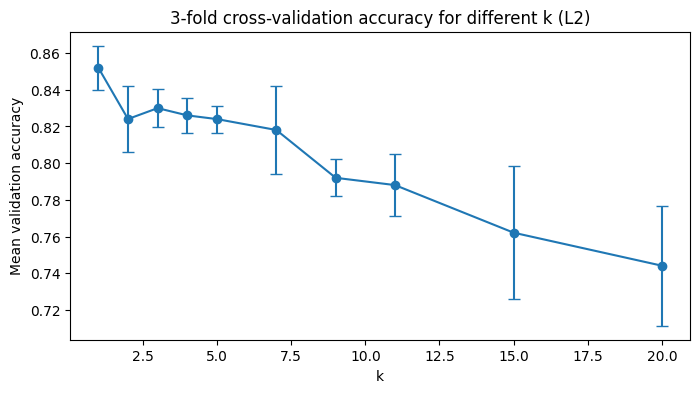

In [20]:
# --- Task 2.2.1: Choosing the best k with 3-fold cross-validation (L2 norm) ---

K_VALUES = [1, 2, 3, 4, 5, 7, 9, 11, 15, 20]
N_FOLDS = 3

# I shuffle the 500 training indices once (fixed seed) and split them into 3 folds
rng = np.random.default_rng(42)
folds = np.array_split(rng.permutation(len(Tr_set)), N_FOLDS)

cv_mean, cv_std = {}, {}
for k in K_VALUES:
    accs = []
    for f in range(N_FOLDS):
        # Fold f is my validation set, the other two folds are my training set
        val_idx = folds[f]
        trn_idx = np.concatenate([folds[j] for j in range(N_FOLDS) if j != f])
        pred = knn_predict(Tr_set[trn_idx], Ltr_set[trn_idx], Tr_set[val_idx], k, 'L2')
        accs.append(np.mean(pred == Ltr_set[val_idx]))
    cv_mean[k], cv_std[k] = np.mean(accs), np.std(accs)
    print(f'k = {k:2d}: validation accuracy = {cv_mean[k]:.3f} (+/- {cv_std[k]:.3f})')

best_k = max(cv_mean, key=cv_mean.get)
print('\nBest k from cross-validation:', best_k)

plt.figure(figsize=(8, 4))
plt.errorbar(K_VALUES, [cv_mean[k] for k in K_VALUES],
             yerr=[cv_std[k] for k in K_VALUES], fmt='o-', capsize=4)
plt.title('3-fold cross-validation accuracy for different k (L2)')
plt.xlabel('k')
plt.ylabel('Mean validation accuracy')
plt.savefig(os.path.join(FIG_DIR, 'knn_cross_validation.png'), bbox_inches='tight')
plt.show()

In [21]:
# --- Task 2.2.2: Final evaluation on the test data with the best k ---

# Only now, after choosing k, I use the test set - and only once.
# I train on all 500 training images.
final_pred = knn_predict(Tr_set, Ltr_set, Test_images, best_k, 'L2')
print(f'Test accuracy with best k = {best_k}:', np.mean(final_pred == L_test))

Test accuracy with best k = 1: 0.8294
